# ATSA Project — Multiple Seasonalities in Hourly Solar Generation using Prophet

1. Data Preparation
2. Data Quality Check
3. Exploratory Analysis
4. Seasonal Pattern Analysis
5. ACF Analysis
6. Seasonal-Naive Baseline
7. Prophet Models
8. Model Comparison
9. Residual Diagnostics
10. Conclusion


# Project Objective and Research Question

### Objective
To analyse hourly German solar-power generation, identify its major seasonal patterns, and evaluate how explicitly modelling those patterns affects forecasting accuracy using Prophet.

### Research Question
**Can Prophet effectively model the multiple seasonalities present in hourly solar generation, and does adding daily and yearly seasonality improve forecast accuracy?**

### Secondary Question
How does the multi-seasonal Prophet model compare with a simple **seasonal-naive benchmark** that predicts each hour using the same hour from the previous day?


# Dataset and Source

### Source
**Open Power System Data (OPSD) — Time Series package, version 2020-10-06**

Dataset page: `https://data.open-power-system-data.org/time_series/2020-10-06`

### Variable used
`DE_solar_generation_actual`

This variable represents **actual solar generation in Germany in MW**.

### Why this dataset was selected
- Hourly observations
- Multi-year time coverage
- Strong daily solar cycle
- Enough history to investigate annual seasonality
- Actual observed generation rather than a simulated series

The wider OPSD file contains many countries and electricity variables, but this project isolates Germany's actual solar-generation time series.


# 1. Data Preparation

### What we do
Load the dataset, keep only Germany actual solar generation, rename the columns for Prophet, and convert the timestamp to datetime.

### Why
The raw file contains many countries and variables. We only need `ds` = time and `y` = solar generation.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("time_series_60min_singleindex_filtered.csv", usecols=["utc_timestamp", "DE_solar_generation_actual"])

# Keep only Germany hourly solar generation
solar = df[["utc_timestamp", "DE_solar_generation_actual"]].copy()

# Prophet uses ds for timestamp and y for target
solar = solar.rename(columns={
    "utc_timestamp": "ds",
    "DE_solar_generation_actual": "y"
})

# Convert text timestamp to datetime
solar["ds"] = pd.to_datetime(solar["ds"], utc=True)
solar.head()


,ds,y
0,2014-12-31 23:00:00+00:00,NaN
1,2015-01-01 00:00:00+00:00,NaN
2,2015-01-01 01:00:00+00:00,NaN
3,2015-01-01 02:00:00+00:00,NaN
4,2015-01-01 03:00:00+00:00,NaN


# 2. Data Quality Check

### What we do
Check the time range, missing values, duplicates, hourly spacing and basic statistics.

### Why
A time-series model needs correctly ordered, regularly spaced observations.


In [3]:
print("Start:", solar["ds"].min())
print("End:", solar["ds"].max())

print("\nMissing values:")
print(solar.isna().sum())
print("Missing %:", round(solar["y"].isna().mean() * 100, 3))

print("\nDuplicate timestamps:", solar["ds"].duplicated().sum())

print("\nMost common time gaps:")
print(solar["ds"].diff().value_counts().head())

print("\nGeneration statistics:")
print(solar["y"].describe())

Start: 2014-12-31 23:00:00+00:00
End: 2020-09-30 23:00:00+00:00

Missing values:
ds      0
y     104
dtype: int64
Missing %: 0.206

Duplicate timestamps: 0

Most common time gaps:
ds
0 days 01:00:00    50400
Name: count, dtype: int64

Generation statistics:
count    50297.000000
mean      4566.042905
std       6940.267590
min          0.000000
25%          0.000000
50%        173.000000
75%       7342.000000
max      32947.000000
Name: y, dtype: float64


# 3. Exploratory Time-Series Analysis

### What we do
Plot the complete series and then zoom into one week.

### Why
The full plot shows long-term behaviour; the weekly plot makes the repeating daily cycle visible.


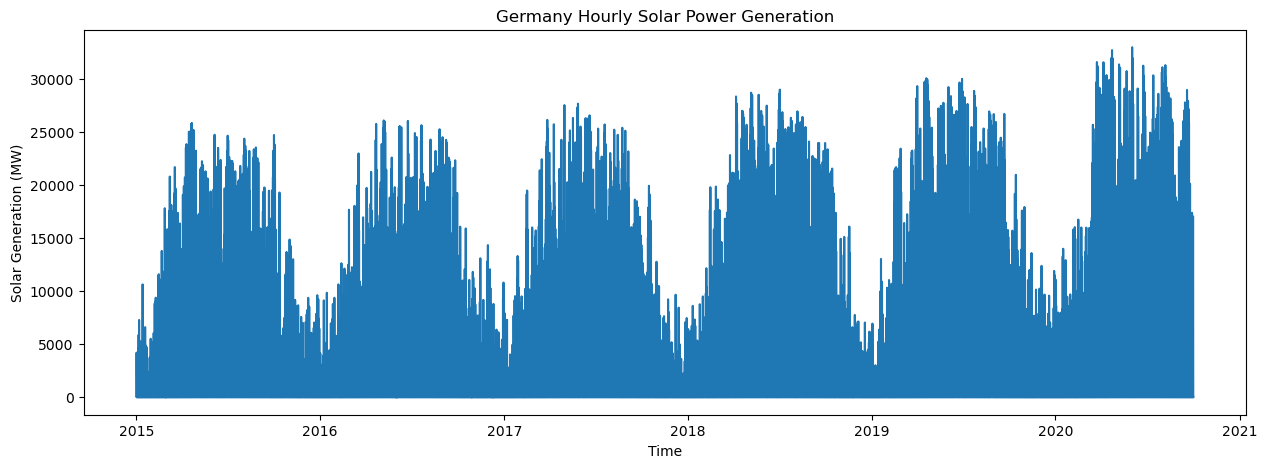

In [4]:
# Full series
plt.figure(figsize=(15, 5))
plt.plot(solar["ds"], solar["y"])
plt.title("Germany Hourly Solar Power Generation")
plt.xlabel("Time")
plt.ylabel("Solar Generation (MW)")
plt.show()

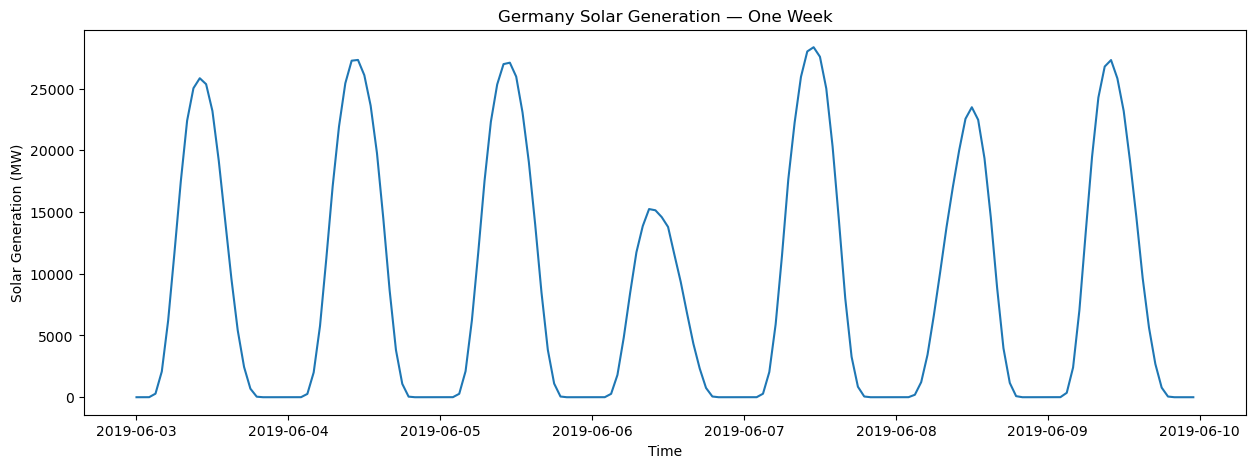

In [5]:
# One-week zoom
week = solar[(solar["ds"] >= "2019-06-03") & (solar["ds"] < "2019-06-10")]

plt.figure(figsize=(15, 5))
plt.plot(week["ds"], week["y"])
plt.title("Germany Solar Generation — One Week")
plt.xlabel("Time")
plt.ylabel("Solar Generation (MW)")
plt.show()

# 4. Seasonal Pattern Analysis

### What we do
Study average generation by hour, average generation by month, and compare daily patterns across different months.

### Why
This gives visual evidence of both daily and annual seasonality.


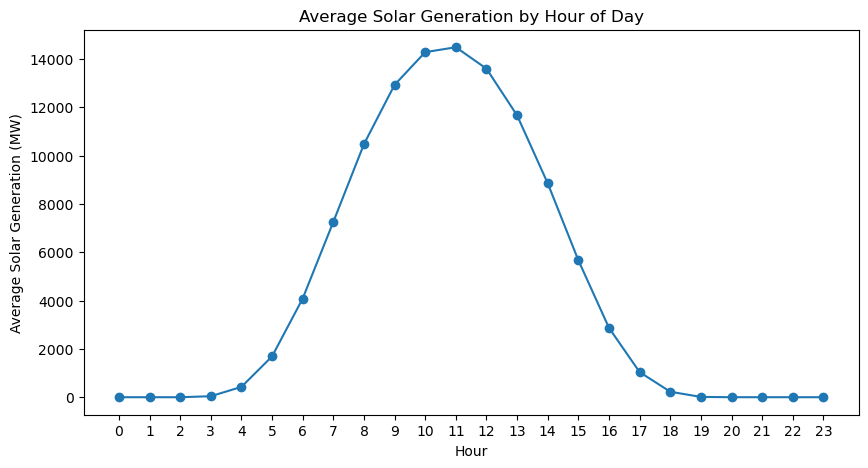

In [6]:
# Add seasonal time variables
solar["hour"] = solar["ds"].dt.hour
solar["month"] = solar["ds"].dt.month

# Typical 24-hour profile
hourly_profile = solar.groupby("hour")["y"].mean()

plt.figure(figsize=(10, 5))
plt.plot(hourly_profile.index, hourly_profile.values, marker="o")
plt.title("Average Solar Generation by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Average Solar Generation (MW)")
plt.xticks(range(24))
plt.show()

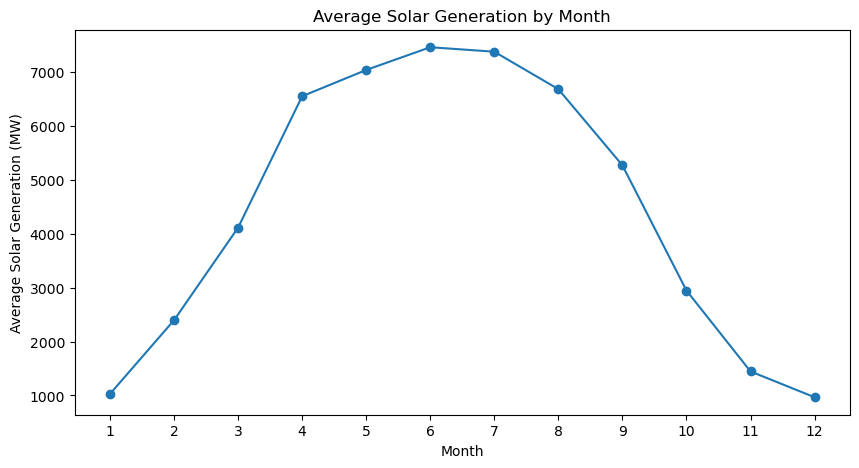

In [7]:
# Average generation by month
monthly_profile = solar.groupby("month")["y"].mean()

plt.figure(figsize=(10, 5))
plt.plot(monthly_profile.index, monthly_profile.values, marker="o")
plt.title("Average Solar Generation by Month")
plt.xlabel("Month")
plt.ylabel("Average Solar Generation (MW)")
plt.xticks(range(1, 13))
plt.show()

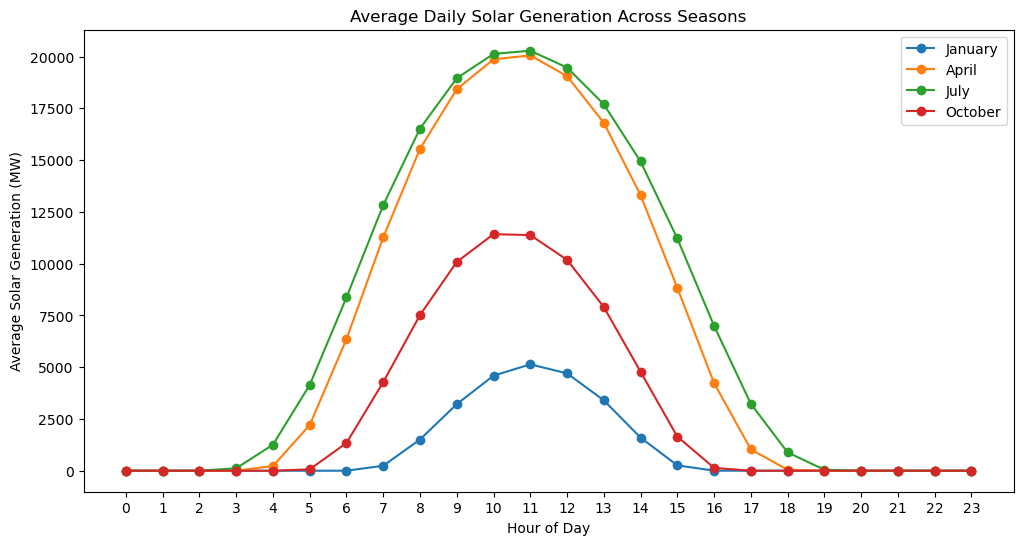

In [8]:
# Compare the typical daily curve across representative seasons
month_names = {1: "January", 4: "April", 7: "July", 10: "October"}

plt.figure(figsize=(12, 6))

for month, name in month_names.items():
    profile = solar[solar["month"] == month].groupby("hour")["y"].mean()
    plt.plot(profile.index, profile.values, marker="o", label=name)

plt.title("Average Daily Solar Generation Across Seasons")
plt.xlabel("Hour of Day")
plt.ylabel("Average Solar Generation (MW)")
plt.xticks(range(24))
plt.legend()
plt.show()

### Initial Finding
The series shows a strong 24-hour solar cycle and clear variation across the year. The daily curve also changes by season, supporting the idea of multiple seasonalities.


# 5. ACF Analysis

### What we do
Use the Autocorrelation Function to measure the relationship between current solar generation and previous hourly values.

### Why
For hourly data, peaks at 24, 48, 72, ... hours statistically support the daily seasonal cycle.


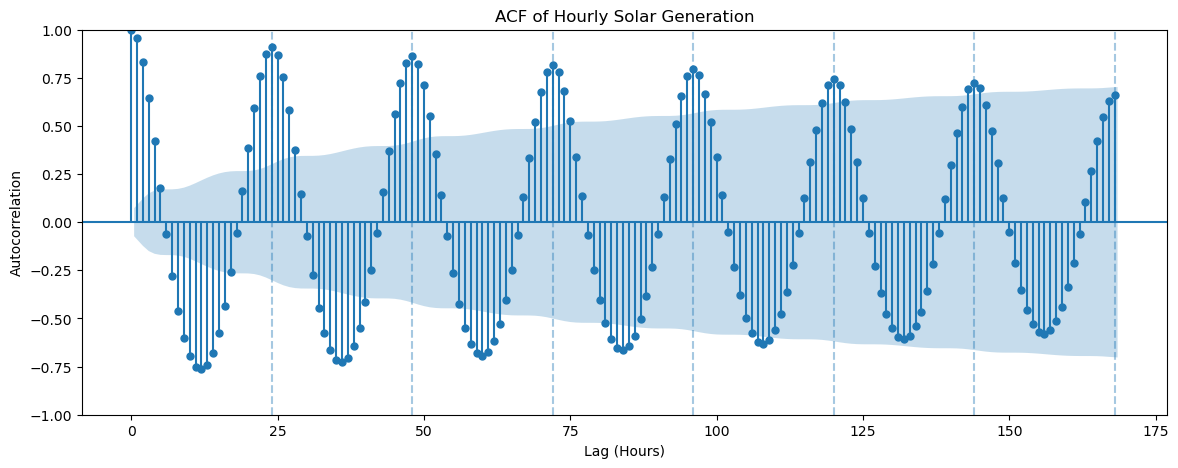

In [9]:
from statsmodels.graphics.tsaplots import plot_acf

# One month is enough to clearly show daily autocorrelation
acf_data = solar[(solar["ds"] >= "2019-06-01") & (solar["ds"] < "2019-07-01")]["y"].dropna()

fig, ax = plt.subplots(figsize=(14, 5))
plot_acf(acf_data, lags=168, ax=ax)

for lag in [24, 48, 72, 96, 120, 144, 168]:
    ax.axvline(lag, linestyle="--", alpha=0.4)

plt.title("ACF of Hourly Solar Generation")
plt.xlabel("Lag (Hours)")
plt.ylabel("Autocorrelation")
plt.show()

### ACF Interpretation
Repeated peaks near multiples of 24 hours confirm strong daily seasonal dependence.


# 6. Seasonal-Naive Baseline

### What we do
Use the previous day’s same-hour value as the forecast:

**ŷₜ = Yₜ₋₂₄**

### Why
This provides a simple benchmark that Prophet should try to beat.


In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Keep the original hourly rows so shift(24) really means 24 hours earlier
baseline = solar[["ds", "y"]].copy()
baseline["naive_forecast"] = baseline["y"].shift(24)

# Evaluate on the complete year 2019
baseline_test = baseline[
    (baseline["ds"] >= "2019-01-01") &
    (baseline["ds"] < "2020-01-01")
].dropna(subset=["y", "naive_forecast"]).copy()

mae_naive = mean_absolute_error(baseline_test["y"], baseline_test["naive_forecast"])
rmse_naive = np.sqrt(mean_squared_error(baseline_test["y"], baseline_test["naive_forecast"]))

print("Seasonal-Naive Baseline")
print(f"MAE  : {mae_naive:.2f} MW")
print(f"RMSE : {rmse_naive:.2f} MW")

Seasonal-Naive Baseline
MAE  : 1136.62 MW
RMSE : 2477.54 MW


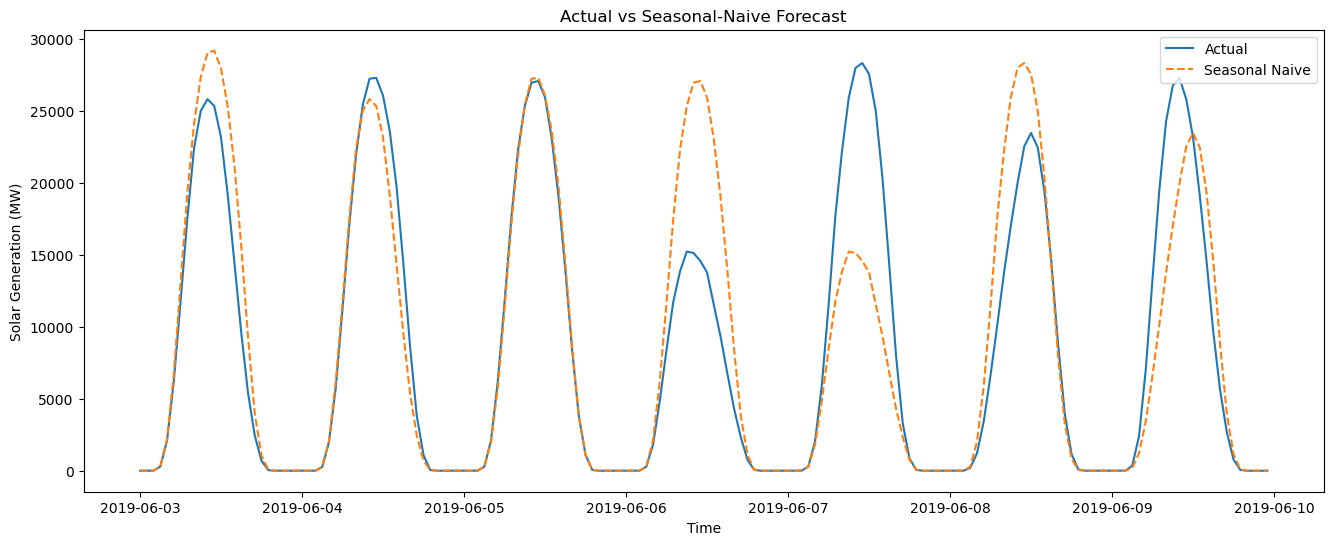

In [11]:
# Visual check of the baseline for one week
baseline_week = baseline_test[
    (baseline_test["ds"] >= "2019-06-03") &
    (baseline_test["ds"] < "2019-06-10")
]

plt.figure(figsize=(16, 6))
plt.plot(baseline_week["ds"], baseline_week["y"], label="Actual")
plt.plot(baseline_week["ds"], baseline_week["naive_forecast"], label="Seasonal Naive", linestyle="--")
plt.title("Actual vs Seasonal-Naive Forecast")
plt.xlabel("Time")
plt.ylabel("Solar Generation (MW)")
plt.legend()
plt.show()

# 7. Prophet Forecasting Models

### What we do
Build three models:
1. Trend only
2. Trend + daily seasonality
3. Trend + daily + yearly seasonality

### Why
This shows whether adding the seasonal components actually improves forecasting.


In [12]:
from prophet import Prophet

# Prophet input
prophet_data = solar[["ds", "y"]].dropna().copy()
prophet_data["ds"] = prophet_data["ds"].dt.tz_convert(None)

# Train on the past, test on the full year 2019
train = prophet_data[prophet_data["ds"] < "2019-01-01"].copy()
test = prophet_data[(prophet_data["ds"] >= "2019-01-01") & (prophet_data["ds"] < "2020-01-01")].copy()

print("Training:", train["ds"].min(), "to", train["ds"].max())
print("Testing :", test["ds"].min(), "to", test["ds"].max())

Note: you may need to restart the kernel to use updated packages.
Training: 2015-01-01 07:00:00 to 2018-12-31 23:00:00
Testing : 2019-01-01 00:00:00 to 2019-12-31 23:00:00


In [13]:
# MODEL 1 — Trend only
model_1 = Prophet(daily_seasonality=False, weekly_seasonality=False, yearly_seasonality=False)
model_1.fit(train)
forecast_1 = model_1.predict(test[["ds"]])

mae_model_1 = mean_absolute_error(test["y"], forecast_1["yhat"])
rmse_model_1 = np.sqrt(mean_squared_error(test["y"], forecast_1["yhat"]))

print("Trend Only")
print(f"MAE  : {mae_model_1:.2f} MW")
print(f"RMSE : {rmse_model_1:.2f} MW")

17:57:52 - cmdstanpy - INFO - Chain [1] start processing
17:58:13 - cmdstanpy - INFO - Chain [1] done processing


Trend Only
MAE  : 5227.64 MW
RMSE : 8411.00 MW


In [14]:
# MODEL 2 — Trend + daily seasonality
model_2 = Prophet(daily_seasonality=True, weekly_seasonality=False, yearly_seasonality=False)
model_2.fit(train)
forecast_2 = model_2.predict(test[["ds"]])

mae_model_2 = mean_absolute_error(test["y"], forecast_2["yhat"])
rmse_model_2 = np.sqrt(mean_squared_error(test["y"], forecast_2["yhat"]))

print("Daily Seasonality")
print(f"MAE  : {mae_model_2:.2f} MW")
print(f"RMSE : {rmse_model_2:.2f} MW")

17:58:23 - cmdstanpy - INFO - Chain [1] start processing
17:58:58 - cmdstanpy - INFO - Chain [1] done processing


Daily Seasonality
MAE  : 5794.46 MW
RMSE : 7077.20 MW


In [15]:
# MODEL 3 — Trend + daily + yearly seasonality
model_3 = Prophet(daily_seasonality=True, weekly_seasonality=False, yearly_seasonality=True)
model_3.fit(train)
forecast_3 = model_3.predict(test[["ds"]])

results_3 = test[["ds", "y"]].copy()
results_3["yhat"] = forecast_3["yhat"].values

mae_model_3 = mean_absolute_error(results_3["y"], results_3["yhat"])
rmse_model_3 = np.sqrt(mean_squared_error(results_3["y"], results_3["yhat"]))

print("Daily + Yearly Seasonality")
print(f"MAE  : {mae_model_3:.2f} MW")
print(f"RMSE : {rmse_model_3:.2f} MW")

17:59:14 - cmdstanpy - INFO - Chain [1] start processing
17:59:27 - cmdstanpy - INFO - Chain [1] done processing


Daily + Yearly Seasonality
MAE  : 2907.83 MW
RMSE : 3762.52 MW


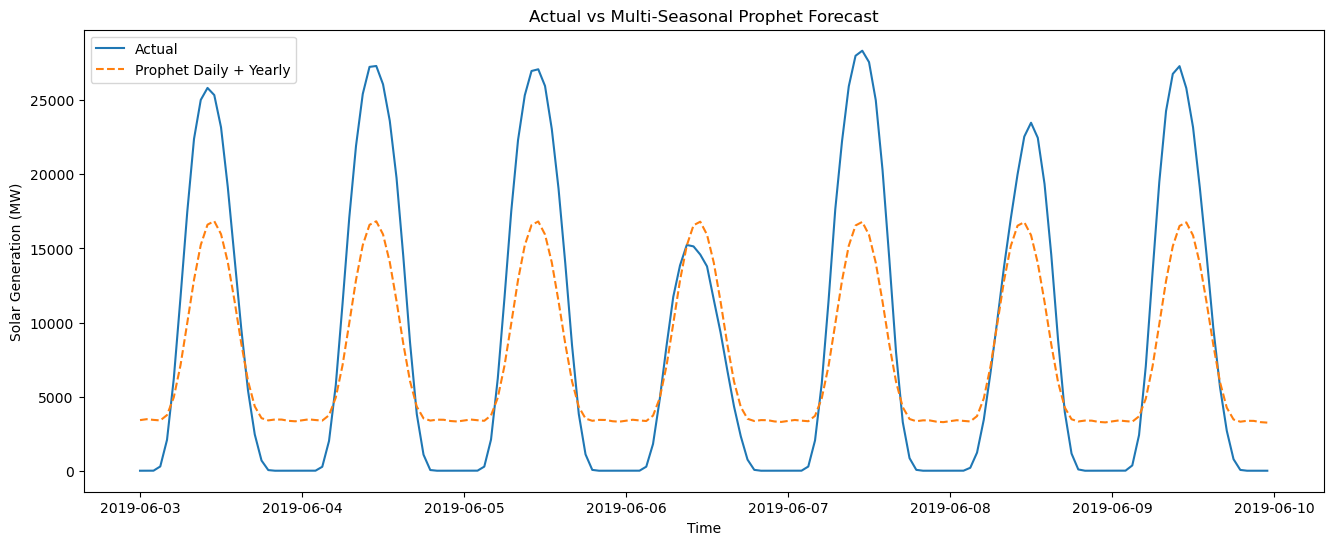

In [16]:
# Final Prophet forecast for one representative week
results_week = results_3[(results_3["ds"] >= "2019-06-03") & (results_3["ds"] < "2019-06-10")]

plt.figure(figsize=(16, 6))
plt.plot(results_week["ds"], results_week["y"], label="Actual")
plt.plot(results_week["ds"], results_week["yhat"], label="Prophet Daily + Yearly", linestyle="--")
plt.title("Actual vs Multi-Seasonal Prophet Forecast")
plt.xlabel("Time")
plt.ylabel("Solar Generation (MW)")
plt.legend()
plt.show()

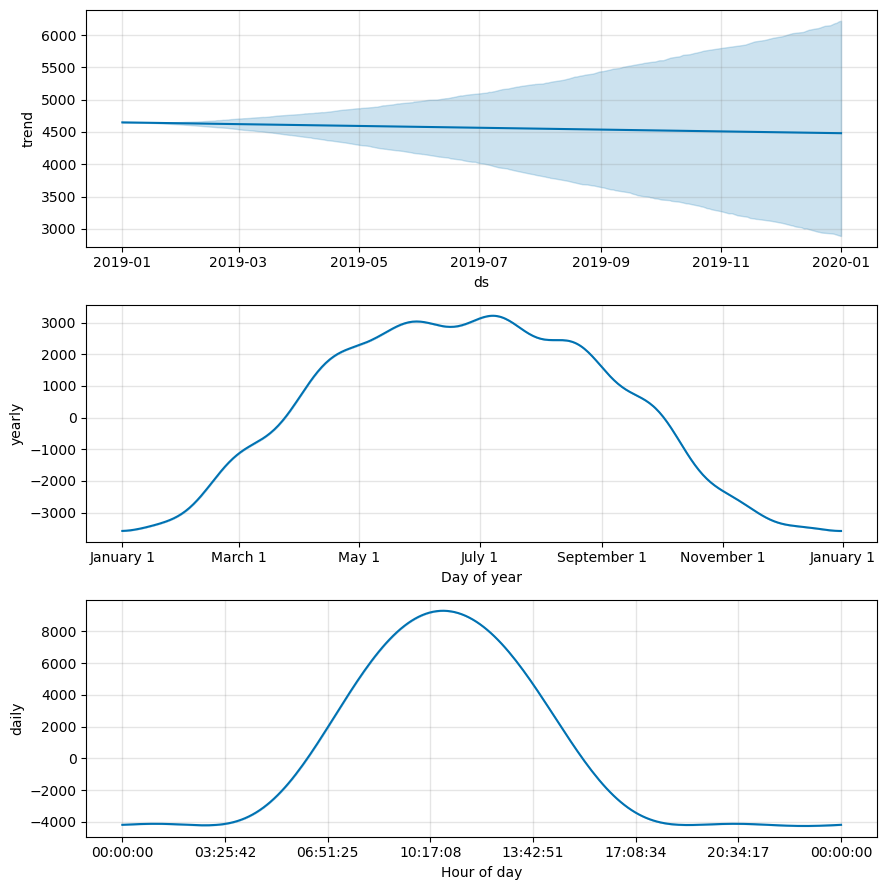

In [17]:
# Show the trend, daily and yearly components learned by Prophet
model_3.plot_components(forecast_3)
plt.show()

# 8. Model Comparison

### What we do
Compare the baseline and all Prophet models using MAE and RMSE.

### Why
This answers whether modelling multiple seasonalities improves forecast accuracy.


In [18]:
final_comparison = pd.DataFrame({
    "Model": [
        "Seasonal Naive",
        "Prophet Trend Only",
        "Prophet Daily",
        "Prophet Daily + Yearly"
    ],
    "MAE (MW)": [mae_naive, mae_model_1, mae_model_2, mae_model_3],
    "RMSE (MW)": [rmse_naive, rmse_model_1, rmse_model_2, rmse_model_3]
})

print(final_comparison)

best_model = final_comparison.loc[final_comparison["RMSE (MW)"].idxmin()]
print("\nLowest-RMSE model:", best_model["Model"])
print("RMSE:", round(best_model["RMSE (MW)"], 2), "MW")

                    Model     MAE (MW)    RMSE (MW)
0          Seasonal Naive  1136.622717  2477.540140
1      Prophet Trend Only  5227.640739  8411.004127
2           Prophet Daily  5794.461511  7077.199909
3  Prophet Daily + Yearly  2907.827768  3762.516231

Lowest-RMSE model: Seasonal Naive
RMSE: 2477.54 MW


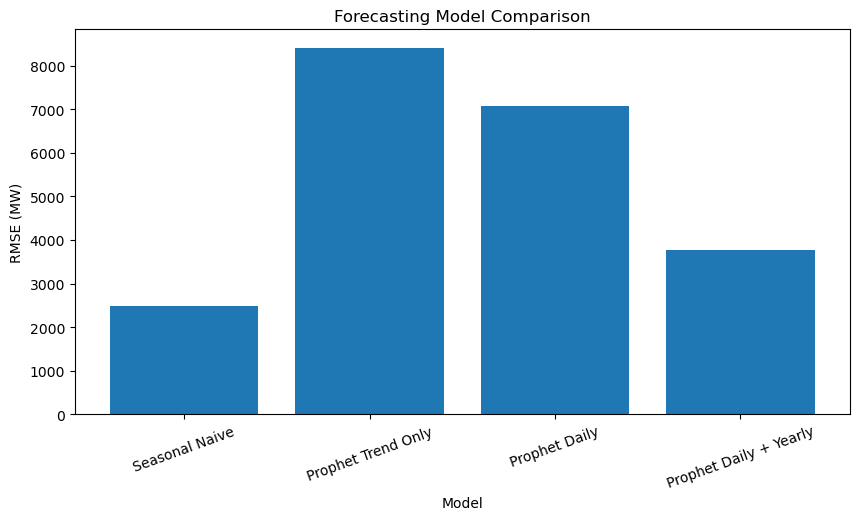

In [19]:
plt.figure(figsize=(10, 5))
plt.bar(final_comparison["Model"], final_comparison["RMSE (MW)"])
plt.title("Forecasting Model Comparison")
plt.xlabel("Model")
plt.ylabel("RMSE (MW)")
plt.xticks(rotation=20)
plt.show()

# 9. Residual Diagnostics

### What we do
Examine the remaining errors from the Daily + Yearly Prophet model using residual ACF and error by hour.

### Why
This checks whether predictable time structure remains after forecasting.


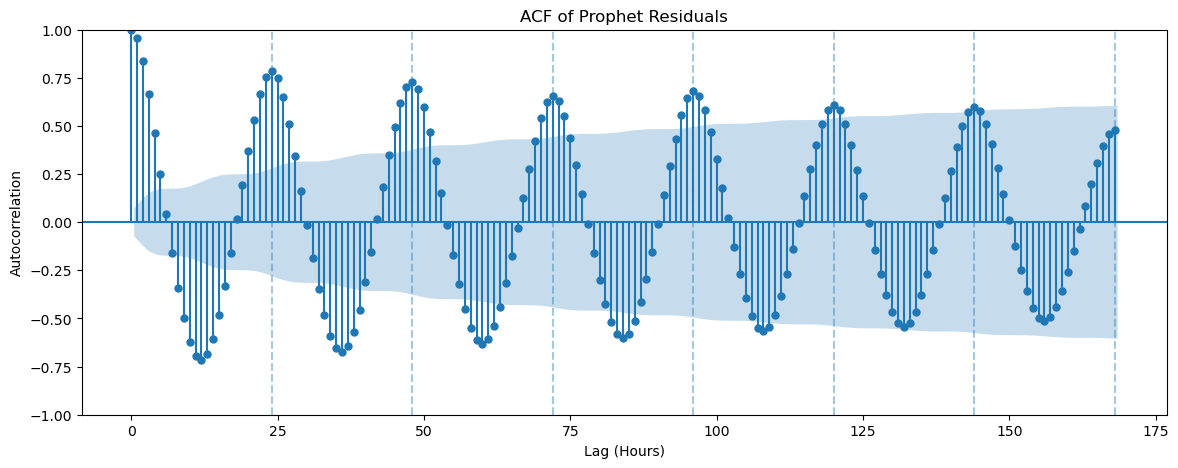

In [20]:
# Residual = Actual - Predicted
results_3["residual"] = results_3["y"] - results_3["yhat"]

residual_sample = results_3[
    (results_3["ds"] >= "2019-06-01") &
    (results_3["ds"] < "2019-07-01")
]["residual"].dropna()

fig, ax = plt.subplots(figsize=(14, 5))
plot_acf(residual_sample, lags=168, ax=ax)

for lag in [24, 48, 72, 96, 120, 144, 168]:
    ax.axvline(lag, linestyle="--", alpha=0.4)

plt.title("ACF of Prophet Residuals")
plt.xlabel("Lag (Hours)")
plt.ylabel("Autocorrelation")
plt.show()

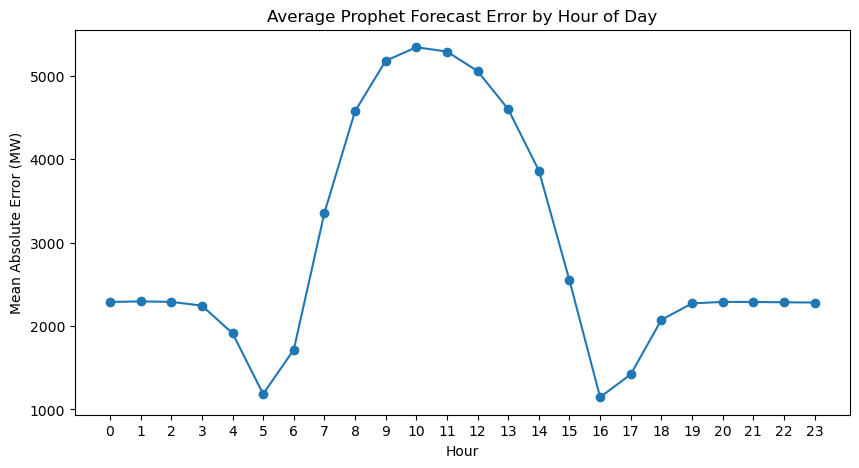

In [21]:
# Find when during the day Prophet makes the largest errors
results_3["hour"] = results_3["ds"].dt.hour
results_3["absolute_error"] = abs(results_3["y"] - results_3["yhat"])

error_by_hour = results_3.groupby("hour")["absolute_error"].mean()

plt.figure(figsize=(10, 5))
plt.plot(error_by_hour.index, error_by_hour.values, marker="o")
plt.title("Average Prophet Forecast Error by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Mean Absolute Error (MW)")
plt.xticks(range(24))
plt.show()

# 10. Limitations

1. **Weather variables are not included.**  
   Prophet learns temporal patterns but does not directly know future cloud cover, irradiance, temperature or storms.

2. **Installed solar capacity changes over time.**  
   Raw national generation can rise because more solar capacity is installed, not only because seasonal conditions change.

3. **The baseline and Prophet do not use exactly the same information set.**  
   The seasonal-naive forecast uses the actual value from 24 hours earlier throughout the test year, while Prophet is trained on pre-2019 data and forecasts the 2019 holdout.

4. **A full production forecasting system would require more rigorous rolling evaluation.**  
   The current project is designed to demonstrate the ATSA workflow and the effect of multiple seasonalities clearly.


# 11. Future Scope

Possible extensions include:

- Rolling-origin / time-series cross-validation
- Weather regressors such as irradiance, cloud cover and temperature
- Capacity-normalised solar generation
- Prophet hyperparameter tuning
- Testing custom Fourier orders
- Comparing Prophet with ARIMA/SARIMA, exponential smoothing or machine-learning models

These are extensions rather than requirements for the core project.


# 12. References

1. Open Power System Data. **Time Series — Version 2020-10-06.**  
   `https://data.open-power-system-data.org/time_series/2020-10-06`

2. Prophet Documentation. **Forecasting at Scale / Quick Start / Seasonality.**  
   `https://facebook.github.io/prophet/`

3. Prophet Quick Start.  
   `https://facebook.github.io/prophet/docs/quick_start.html`

4. Prophet Seasonality Documentation.  
   `https://facebook.github.io/prophet/docs/seasonality%2C_holiday_effects%2C_and_regressors.html`
